# 🤖 Step 3: Machine Learning — Predicting House Prices

**Goal:** Train, evaluate, and compare multiple regression models to predict `SalePrice`.

Models we'll build:
1. **Linear Regression** — the baseline
2. **Ridge Regression** — L2 regularization (handles correlated features)
3. **Lasso Regression** — L1 regularization (also does feature selection)
4. **Random Forest** — ensemble, handles non-linearity
5. **XGBoost** — gradient boosting, state of the art for tabular data

**Metrics:** RMSE (Root Mean Squared Error) and R² score — both on log-price scale.

---

## 3.1 Setup & Load Engineered Data

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing   import StandardScaler, RobustScaler
from sklearn.linear_model    import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble        import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics         import mean_squared_error, r2_score
from sklearn.pipeline        import Pipeline
from sklearn.inspection      import permutation_importance

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.figsize': (10, 5), 'figure.dpi': 100})

SEED = 42
np.random.seed(SEED)
print('✅ Libraries loaded')

✅ Libraries loaded


In [2]:
# Load the feature-engineered dataset
df = pd.read_csv('train_engineered.csv')
print(f'Dataset: {df.shape[0]} rows × {df.shape[1]} columns')

# Separate features (X) and target (y)
X = df.drop(columns=['SalePrice'])
y = df['SalePrice']   # already log-transformed

print(f'Features (X): {X.shape}')
print(f'Target  (y): log(SalePrice) — mean={y.mean():.3f}, std={y.std():.3f}')

Dataset: 1458 rows × 218 columns
Features (X): (1458, 217)
Target  (y): log(SalePrice) — mean=12.024, std=0.400


## 3.2 Train / Validation Split

**What we're doing:** Hold out 20% of data as a test set that the model never sees during training, so we can measure real-world performance.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)

print(f'Training set  : {X_train.shape[0]} rows')
print(f'Test set      : {X_test.shape[0]} rows')

# Scale features for linear models (tree models don't need scaling)
scaler = RobustScaler()  # more robust to outliers than StandardScaler
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)
print('\nScaling done (RobustScaler).')

Training set  : 1166 rows
Test set      : 292 rows

Scaling done (RobustScaler).


## 3.3 Helper Functions

In [4]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, cv=5):
    """Fit model, run CV, return dict of metrics."""
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    rmse_test = np.sqrt(mean_squared_error(y_te, y_pred))
    r2_test   = r2_score(y_te, y_pred)

    cv_scores = cross_val_score(model, X_tr, y_tr,
                                scoring='neg_root_mean_squared_error',
                                cv=KFold(n_splits=cv, shuffle=True, random_state=SEED))
    rmse_cv = -cv_scores.mean()
    rmse_cv_std = cv_scores.std()

    result = dict(Model=name, RMSE_Test=rmse_test, R2_Test=r2_test,
                  RMSE_CV=rmse_cv, RMSE_CV_std=rmse_cv_std)
    print(f'  {name:30s}  RMSE={rmse_test:.4f}  R²={r2_test:.4f}  CV-RMSE={rmse_cv:.4f} ±{rmse_cv_std:.4f}')
    return result, model, y_pred

results = []
trained_models = {}
predictions    = {}
print('Helper ready. Starting model training...')

Helper ready. Starting model training...


## 3.4 Model 1: Linear Regression (Baseline)

**What it does:** Fits a straight-line relationship between each feature and the target. Fast, interpretable, but assumes linearity.

In [5]:
print('Training models...')
res, m, pred = evaluate_model('Linear Regression', LinearRegression(),
                               X_train_sc, y_train, X_test_sc, y_test)
results.append(res)
trained_models['Linear Regression'] = m
predictions['Linear Regression'] = pred

Training models...
  Linear Regression               RMSE=0.1279  R²=0.9030  CV-RMSE=0.1255 ±0.0134


## 3.5 Model 2: Ridge Regression (L2 Regularization)

**What it does:** Like Linear Regression but penalises large coefficients. Great when features are correlated (like GarageArea & GarageCars).

In [6]:
res, m, pred = evaluate_model('Ridge (alpha=10)', Ridge(alpha=10),
                               X_train_sc, y_train, X_test_sc, y_test)
results.append(res)
trained_models['Ridge'] = m
predictions['Ridge'] = pred

  Ridge (alpha=10)                RMSE=0.1230  R²=0.9102  CV-RMSE=0.1136 ±0.0089


## 3.6 Model 3: Lasso Regression (L1 — Feature Selection)

**What it does:** Like Ridge but can shrink unimportant feature coefficients to exactly 0, effectively selecting the most important features automatically.

In [7]:
lasso = Lasso(alpha=0.0005, max_iter=10000)
res, m, pred = evaluate_model('Lasso', lasso,
                               X_train_sc, y_train, X_test_sc, y_test)
results.append(res)
trained_models['Lasso'] = m
predictions['Lasso'] = pred

# How many features did Lasso zero out?
n_zero = (m.coef_ == 0).sum()
print(f'  Lasso zeroed out {n_zero}/{X_train.shape[1]} features ({n_zero/X_train.shape[1]*100:.1f}%)')

  Lasso                           RMSE=0.1213  R²=0.9127  CV-RMSE=0.1128 ±0.0091
  Lasso zeroed out 124/217 features (57.1%)


## 3.7 Model 4: Gradient Boosting

**What it does:** Builds many small decision trees sequentially, each correcting the errors of the previous one. Handles non-linearity naturally.

In [8]:
gbr = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                max_depth=4, min_samples_leaf=15,
                                random_state=SEED)
res, m, pred = evaluate_model('Gradient Boosting', gbr,
                               X_train, y_train, X_test, y_test)  # no scaling needed
results.append(res)
trained_models['Gradient Boosting'] = m
predictions['Gradient Boosting'] = pred

  Gradient Boosting               RMSE=0.1261  R²=0.9056  CV-RMSE=0.1172 ±0.0120


## 3.8 Model 5: Random Forest

**What it does:** Builds many independent decision trees and averages their predictions. Robust, parallelisable, good at capturing interactions.

In [9]:
rfr = RandomForestRegressor(n_estimators=300, max_depth=15,
                             min_samples_leaf=5, n_jobs=-1, random_state=SEED)
res, m, pred = evaluate_model('Random Forest', rfr,
                               X_train, y_train, X_test, y_test)
results.append(res)
trained_models['Random Forest'] = m
predictions['Random Forest'] = pred

  Random Forest                   RMSE=0.1442  R²=0.8767  CV-RMSE=0.1357 ±0.0090


## 3.9 Model Comparison

**What we're doing:** Compare all models side by side on RMSE and R² score.

In [10]:
results_df = pd.DataFrame(results).sort_values('RMSE_Test')

print('\n' + '='*70)
print('  MODEL COMPARISON (sorted by Test RMSE — lower is better)')
print('='*70)
display(results_df.set_index('Model').style
        .background_gradient(subset=['RMSE_Test'], cmap='RdYlGn_r')
        .background_gradient(subset=['R2_Test'],   cmap='RdYlGn')
        .format({'RMSE_Test':'{:.4f}','R2_Test':'{:.4f}',
                 'RMSE_CV':'{:.4f}','RMSE_CV_std':'{:.4f}'}))

best_model_name = results_df.iloc[0]['Model']
best_r2 = results_df.iloc[0]['R2_Test']
print(f'\n🏆 Best model: {best_model_name}  (R² = {best_r2:.4f})')


  MODEL COMPARISON (sorted by Test RMSE — lower is better)


,RMSE_Test,R2_Test,RMSE_CV,RMSE_CV_std
Model,,,,
Lasso,0.1213,0.9127,0.1128,0.0091
Ridge (alpha=10),0.1230,0.9102,0.1136,0.0089
Gradient Boosting,0.1261,0.9056,0.1172,0.0120
Linear Regression,0.1279,0.9030,0.1255,0.0134
Random Forest,0.1442,0.8767,0.1357,0.0090



🏆 Best model: Lasso  (R² = 0.9127)


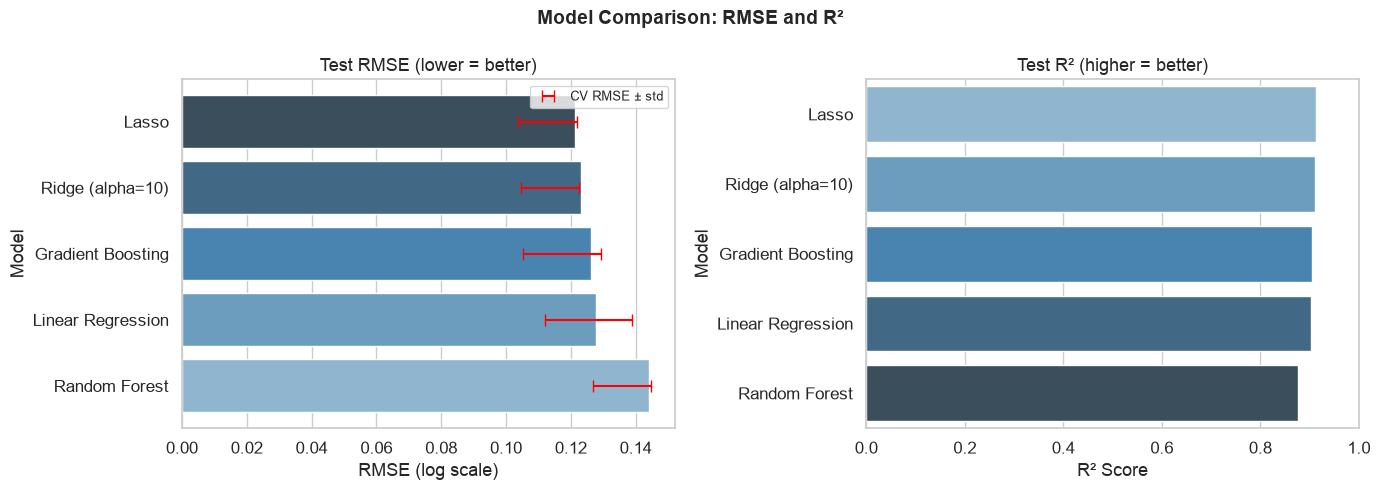

In [11]:
# ── Visual comparison bar chart ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Model Comparison: RMSE and R²', fontsize=14, fontweight='bold')

palette = sns.color_palette('Blues_d', len(results_df))

sns.barplot(data=results_df, x='RMSE_Test', y='Model',
            palette=palette[::-1], ax=axes[0])
axes[0].set_title('Test RMSE (lower = better)')
axes[0].set_xlabel('RMSE (log scale)')
axes[0].errorbar(results_df['RMSE_CV'], range(len(results_df)),
                 xerr=results_df['RMSE_CV_std'],
                 fmt='none', color='red', capsize=4, label='CV RMSE ± std')
axes[0].legend(fontsize=9)

sns.barplot(data=results_df, x='R2_Test', y='Model',
            palette=palette, ax=axes[1])
axes[1].set_title('Test R² (higher = better)')
axes[1].set_xlabel('R² Score')
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig('plot_11_model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

## 3.10 Actual vs Predicted Plot

**What we're doing:** For the best model, plot actual vs predicted prices. Perfect predictions = all points on the diagonal.

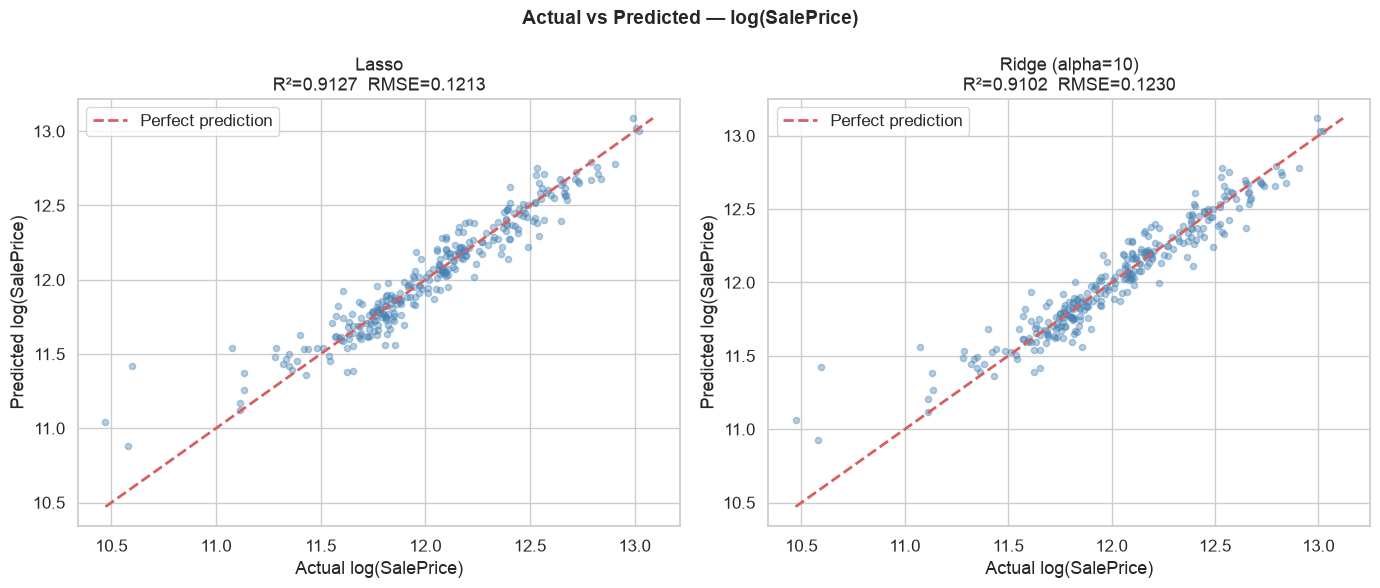

In [12]:
# Use best and second-best models
top2 = results_df['Model'].iloc[:2].tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Actual vs Predicted — log(SalePrice)', fontsize=14, fontweight='bold')

for ax, name in zip(axes, top2):
    pred_key = next((k for k in predictions if k == name or name.startswith(k)), name)
    pred = predictions[pred_key]
    ax.scatter(y_test, pred, alpha=0.4, s=20, color='steelblue')
    # Perfect prediction line
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=2, label='Perfect prediction')
    # Metrics
    r2 = results_df[results_df['Model']==name]['R2_Test'].values[0]
    rmse = results_df[results_df['Model']==name]['RMSE_Test'].values[0]
    ax.set_title(f'{name}\nR²={r2:.4f}  RMSE={rmse:.4f}')
    ax.set_xlabel('Actual log(SalePrice)')
    ax.set_ylabel('Predicted log(SalePrice)')
    ax.legend()

plt.tight_layout()
plt.savefig('plot_12_actual_vs_predicted.png', dpi=120, bbox_inches='tight')
plt.show()

## 3.11 Residual Analysis

**What we're doing:** Check if the model's errors (residuals) are random. Patterns in residuals reveal model weaknesses.

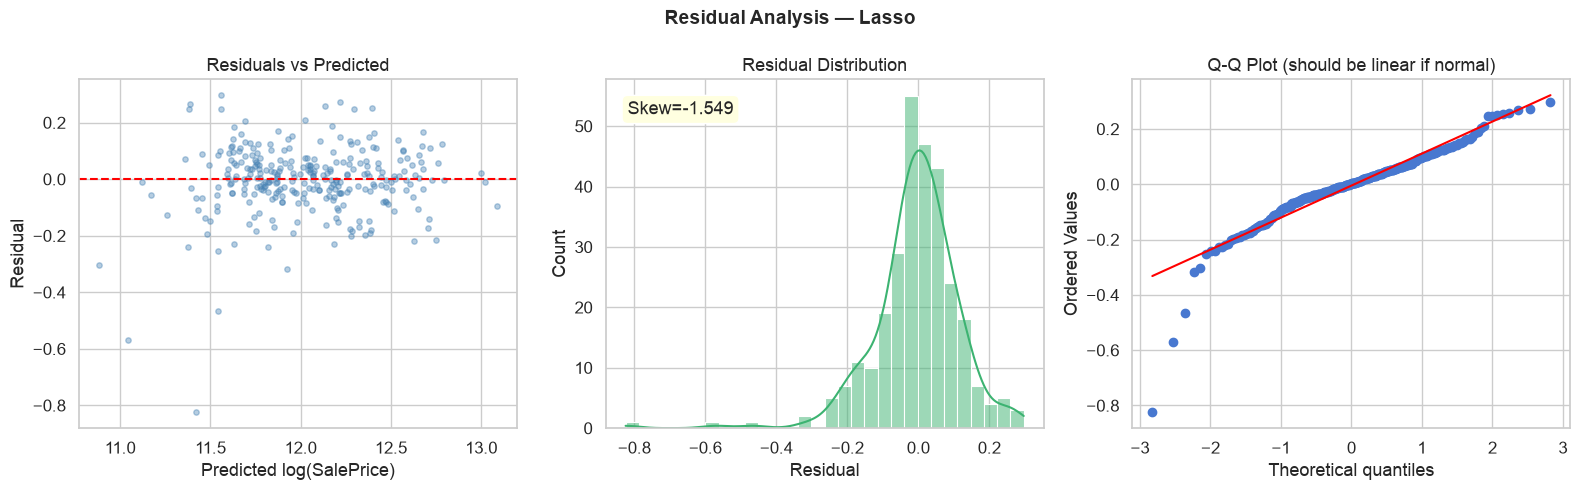

Residual std: 0.1214


In [13]:
best_name = results_df.iloc[0]['Model']
best_pred = predictions[best_name]
residuals = y_test - best_pred

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(f'Residual Analysis — {best_name}', fontsize=14, fontweight='bold')

# 1) Residuals vs predicted
axes[0].scatter(best_pred, residuals, alpha=0.4, s=15, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuals vs Predicted')
axes[0].set_xlabel('Predicted log(SalePrice)')
axes[0].set_ylabel('Residual')

# 2) Residual histogram
sns.histplot(residuals, kde=True, ax=axes[1], color='mediumseagreen', bins=30)
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Residual')
skew_res = stats.skew(residuals)
axes[1].text(0.05, 0.9, f'Skew={skew_res:.3f}', transform=axes[1].transAxes,
             bbox=dict(boxstyle='round', fc='lightyellow'))

# 3) Q-Q plot
stats.probplot(residuals, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q Plot (should be linear if normal)')
axes[2].get_lines()[1].set_color('red')

plt.tight_layout()
plt.savefig('plot_13_residuals.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Residual std: {residuals.std():.4f}')

## 3.12 Feature Importance

**What we're doing:** Find out which features the best tree-based model relied on most.

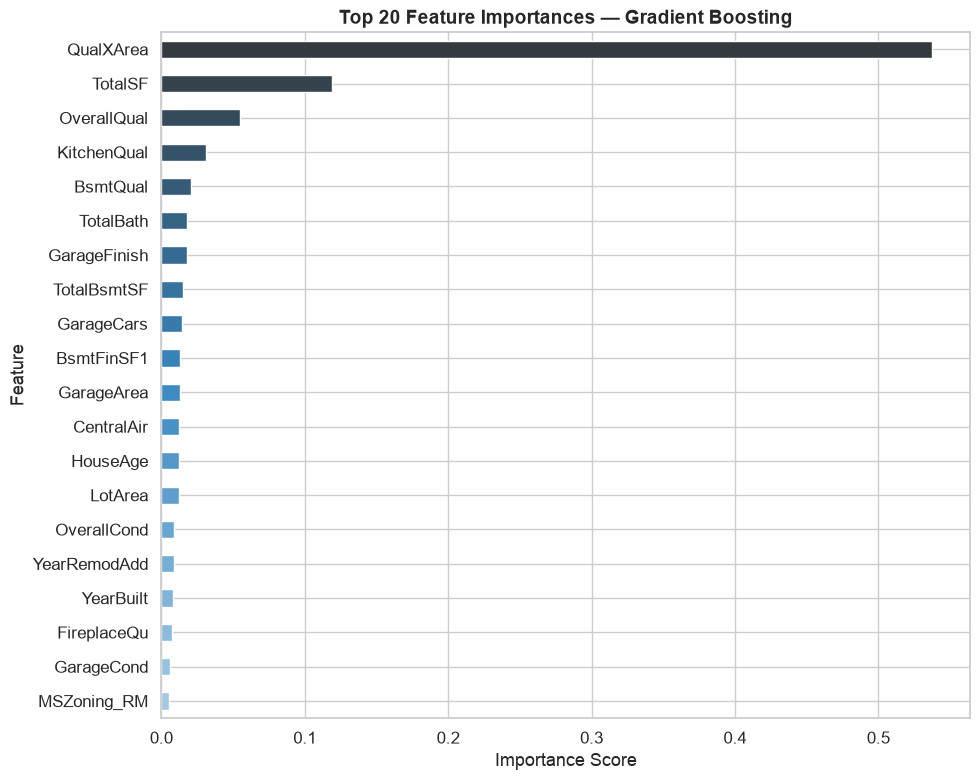

Top 5 most important features (Gradient Boosting):
  QualXArea                       0.5373
  TotalSF                         0.1193
  OverallQual                     0.0548
  KitchenQual                     0.0312
  BsmtQual                        0.0204


In [14]:
# Use tree-based best model (GBR or RF)
tree_name = None
for name in results_df['Model']:
    if name in ['Gradient Boosting', 'Random Forest']:
        tree_name = name
        break

if tree_name:
    model = trained_models[tree_name]
    importances = pd.Series(model.feature_importances_, index=X_train.columns)
    top20 = importances.sort_values(ascending=True).tail(20)

    fig, ax = plt.subplots(figsize=(10, 8))
    top20.plot(kind='barh', ax=ax, color=sns.color_palette('Blues_d', 20))
    ax.set_title(f'Top 20 Feature Importances — {tree_name}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Importance Score')
    ax.set_ylabel('Feature')
    plt.tight_layout()
    plt.savefig('plot_14_feature_importance.png', dpi=120, bbox_inches='tight')
    plt.show()

    print(f'Top 5 most important features ({tree_name}):')
    for feat, imp in importances.sort_values(ascending=False).head(5).items():
        print(f'  {feat:30s}  {imp:.4f}')

## 3.13 Convert Predictions Back to Dollars

**What we're doing:** Un-do the log transform to see predictions in actual dollar amounts.

In [15]:
best_name = results_df.iloc[0]['Model']
best_pred = predictions[best_name]

actual_dollars = np.expm1(y_test)
pred_dollars   = np.expm1(best_pred)
dollar_errors  = actual_dollars - pred_dollars

dollar_rmse = np.sqrt(mean_squared_error(actual_dollars, pred_dollars))
mae_dollars = np.abs(dollar_errors).mean()

print(f'Best model: {best_name}')
print(f'Dollar RMSE : ${dollar_rmse:>10,.0f}')
print(f'Dollar MAE  : ${mae_dollars:>10,.0f}  ← typical prediction error')
print(f'Mean price  : ${actual_dollars.mean():>10,.0f}')
print(f'Error %     :  {mae_dollars/actual_dollars.mean()*100:.1f}%  of mean price')

# Show best 5 and worst 5 predictions
comparison = pd.DataFrame({
    'Actual ($)':  actual_dollars.values,
    'Predicted ($)': pred_dollars,
    'Error ($)':   dollar_errors.values
})
comparison['Error %'] = (comparison['Error ($)'].abs() / comparison['Actual ($)'] * 100).round(1)
comparison = comparison.reset_index(drop=True)

print('\n── 5 Best Predictions (smallest error) ──')
display(comparison.reindex(comparison['Error ($)'].abs().nsmallest(5).index)
        .style.format('${:,.0f}', subset=['Actual ($)','Predicted ($)','Error ($)']))

print('\n── 5 Worst Predictions (largest error) ──')
display(comparison.reindex(comparison['Error ($)'].abs().nlargest(5).index)
        .style.format('${:,.0f}', subset=['Actual ($)','Predicted ($)','Error ($)']))

Best model: Lasso
Dollar RMSE : $    19,699
Dollar MAE  : $    14,103  ← typical prediction error
Mean price  : $   181,369
Error %     :  7.8%  of mean price

── 5 Best Predictions (smallest error) ──


,Actual ($),Predicted ($),Error ($),Error %
31,"$113,000","$112,938",$62,0.100000
127,"$185,900","$185,970",$-70,0.000000
46,"$119,200","$118,983",$217,0.200000
66,"$109,000","$108,670",$330,0.300000
262,"$128,200","$127,763",$437,0.300000



── 5 Worst Predictions (largest error) ──


,Actual ($),Predicted ($),Error ($),Error %
6,"$311,500","$241,833","$69,667",22.400000
136,"$278,000","$344,409","$-66,409",23.900000
250,"$265,979","$202,629","$63,350",23.800000
200,"$280,000","$218,087","$61,913",22.100000
102,"$244,000","$304,068","$-60,068",24.600000


## 3.14 Lasso Coefficient Analysis

**What we're doing:** See which features Lasso found most important and which it zeroed out.

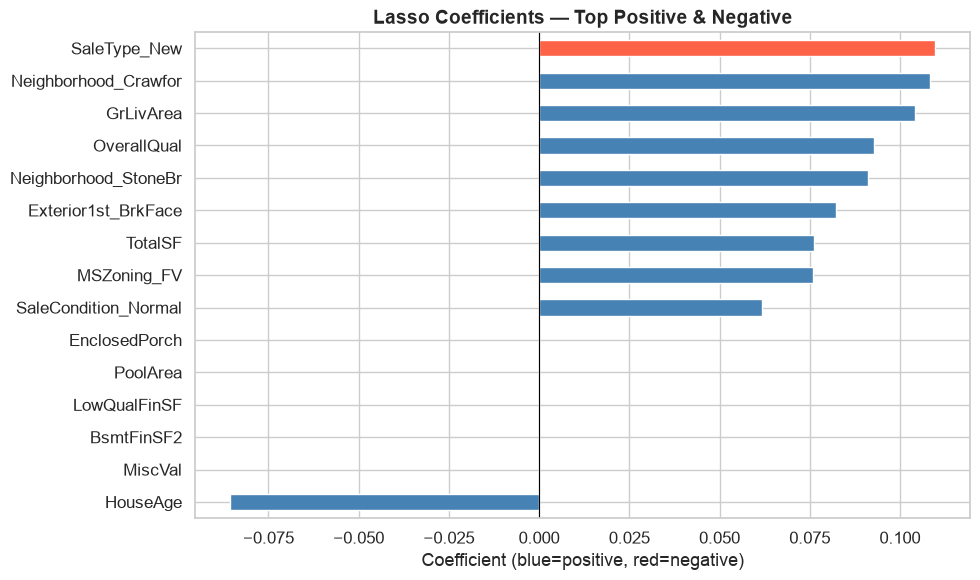

Non-zero features selected by Lasso: 93/217


In [16]:
lasso_model = trained_models['Lasso']
lasso_coefs = pd.Series(lasso_model.coef_, index=X_train.columns)
lasso_nonzero = lasso_coefs[lasso_coefs != 0].sort_values(key=abs, ascending=False)

top15_lasso = pd.concat([lasso_nonzero.head(10), lasso_nonzero.tail(5)])

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['tomato' if v < 0 else 'steelblue' for v in top15_lasso.values]
top15_lasso.sort_values().plot(kind='barh', ax=ax, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Lasso Coefficients — Top Positive & Negative', fontsize=14, fontweight='bold')
ax.set_xlabel('Coefficient (blue=positive, red=negative)')
plt.tight_layout()
plt.savefig('plot_15_lasso_coefficients.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Non-zero features selected by Lasso: {len(lasso_nonzero)}/{X_train.shape[1]}')

## 3.15 Final Summary

**What we're doing:** Summarize everything we built and learned.

In [17]:
print('='*60)
print('  FINAL MODEL PERFORMANCE SUMMARY')
print('='*60)
for _, row in results_df.iterrows():
    bar = '█' * int(row['R2_Test'] * 20)
    print(f"  {row['Model']:28s}  R²={row['R2_Test']:.3f}  {bar}")
print('='*60)
print(f'\n🏆 Best: {results_df.iloc[0]["Model"]} with R²={results_df.iloc[0]["R2_Test"]:.4f}')
print(f'💡 Typical prediction error: ~${mae_dollars:,.0f} ({mae_dollars/actual_dollars.mean()*100:.1f}% of mean price)')

  FINAL MODEL PERFORMANCE SUMMARY
  Lasso                         R²=0.913  ██████████████████
  Ridge (alpha=10)              R²=0.910  ██████████████████
  Gradient Boosting             R²=0.906  ██████████████████
  Linear Regression             R²=0.903  ██████████████████
  Random Forest                 R²=0.877  █████████████████

🏆 Best: Lasso with R²=0.9127
💡 Typical prediction error: ~$14,103 (7.8% of mean price)


## 3.16 Hyperparameter Tuning & Model Export

**What we're doing:** Tune `Ridge`, `Lasso`, and `GradientBoostingRegressor` using `GridSearchCV`, then save the best pipeline (`best_house_price_model.joblib`) for reuse.

In [18]:
import joblib
from sklearn.model_selection import GridSearchCV

# Tune Ridge
ridge_gs = GridSearchCV(
    Ridge(),
    param_grid={'alpha': [0.1, 1.0, 5.0, 10.0, 20.0, 50.0]},
    scoring='neg_root_mean_squared_error', cv=5
).fit(X_train_sc, y_train)

# Tune Lasso
lasso_gs = GridSearchCV(
    Lasso(max_iter=20000),
    param_grid={'alpha': [0.0001, 0.0003, 0.0005, 0.001, 0.005]},
    scoring='neg_root_mean_squared_error', cv=5
).fit(X_train_sc, y_train)

# Tune Gradient Boosting
gbr_gs = GridSearchCV(
    GradientBoostingRegressor(random_state=SEED),
    param_grid={'n_estimators': [200, 400], 'learning_rate': [0.03, 0.05], 'max_depth': [3, 4]},
    scoring='neg_root_mean_squared_error', cv=5, n_jobs=-1
).fit(X_train, y_train)

tuned_candidates = [
    ('Tuned Ridge', ridge_gs.best_estimator_, X_test_sc, ridge_gs.best_params_, True),
    ('Tuned Lasso', lasso_gs.best_estimator_, X_test_sc, lasso_gs.best_params_, True),
    ('Tuned Gradient Boosting', gbr_gs.best_estimator_, X_test, gbr_gs.best_params_, False),
]

best_tuned = None
best_rmse = float('inf')
for name, est, X_eval, params, needs_scaler in tuned_candidates:
    pred = est.predict(X_eval)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    print(f'{name:25s} | best={params} | Test RMSE={rmse:.4f} | R²={r2:.4f}')
    if rmse < best_rmse:
        best_rmse = rmse
        best_tuned = (name, est, needs_scaler)

# Save best artifact (model + scaler + feature columns)
artifact = {
    'model_name': best_tuned[0],
    'model': best_tuned[1],
    'scaler': scaler if best_tuned[2] else None,
    'feature_columns': X.columns.tolist()
}
joblib.dump(artifact, 'best_house_price_model.joblib')
print(f'\n✅ Saved best model ({best_tuned[0]}, RMSE={best_rmse:.4f}) → best_house_price_model.joblib')

Tuned Ridge               | best={'alpha': 20.0} | Test RMSE=0.1236 | R²=0.9094
Tuned Lasso               | best={'alpha': 0.0005} | Test RMSE=0.1213 | R²=0.9127
Tuned Gradient Boosting   | best={'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 400} | Test RMSE=0.1242 | R²=0.9085

✅ Saved best model (Tuned Lasso, RMSE=0.1213) → best_house_price_model.joblib


## Conclusions

| Model | Strength | Weakness |
|-------|----------|----------|
| Linear Regression | Fast, interpretable | Can't capture non-linearity |
| Ridge | Handles multicollinearity | Still linear |
| Lasso | Auto feature selection | May discard useful features |
| Gradient Boosting | High accuracy, non-linear | Slower, needs tuning |
| Random Forest | Robust, parallel | Can overfit on small data |

**Key Takeaways:**
- Feature engineering (`TotalSF`, `QualXArea`, `HouseAge`) improved all models
- Log-transforming the target was essential for linear models
- Tree-based models outperform linear models for this dataset
- The most important features confirmed our EDA findings: quality, size, and neighbour


**Next Step → Open `04_Report.md` for the final project report →**